In [1]:
import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm, lu_factor, lu_solve
from scipy.integrate import solve_ivp
from scipy.optimize import fsolve

def observed_order(N_values, err, n_fit=4):
    N_values = np.asarray(N_values, dtype=float)
    err = np.asarray(err, dtype=float)
    valid = np.isfinite(err) & (err > 0)
    idx = np.where(valid)[0][-min(n_fit, valid.sum()):]
    slope = np.polyfit(np.log(N_values[idx]), np.log(err[idx]), 1)[0]
    return -slope

# explicit Runge-Kutta: generic tableau-driven stepper, reused throughout
EXPLICIT_TABLEAUS = {
    "Heun": (np.array([[0.0, 0.0], [1.0, 0.0]]), np.array([0.5, 0.5]), np.array([0.0, 1.0])),
    "RK3": (np.array([[0.0, 0.0, 0.0], [0.5, 0.0, 0.0], [-1.0, 2.0, 0.0]]),
            np.array([1/6, 2/3, 1/6]), np.array([0.0, 0.5, 1.0])),
    "RK4": (np.array([[0.0, 0.0, 0.0, 0.0], [0.5, 0.0, 0.0, 0.0],
                       [0.0, 0.5, 0.0, 0.0], [0.0, 0.0, 1.0, 0.0]]),
            np.array([1/6, 1/3, 1/3, 1/6]), np.array([0.0, 0.5, 0.5, 1.0])),
}

def explicit_rk_step(f, t, y, dt, A, b, c):
    s = len(b)
    k = [None] * s
    for i in range(s):
        yi = y
        for j in range(i):
            yi = yi + dt * A[i, j] * k[j]
        k[i] = f(t + c[i] * dt, yi)
    return y + dt * sum(b[i] * k[i] for i in range(s))

def explicit_rk_integrate(f, t0, y0, T, N, tableau):
    A, b, c = tableau
    dt = (T - t0) / N
    t, y = t0, np.array(y0, dtype=float)
    for _ in range(N):
        y = explicit_rk_step(f, t, y, dt, A, b, c)
        t += dt
    return y

# Fully implicit Runge-Kutta: all stage equations solved simultaneously with
# fsolve. A DIRK tableau (lower-triangular A) is just a special case of this,
# so the same stepper is reused for both the fully implicit method (Exercise 1)
# and the DIRK methods (Exercise 3).
def implicit_rk_step(f, t, y, dt, A, b, c, k_guess=None):
    y = np.atleast_1d(np.array(y, dtype=float))
    s, n = len(b), y.size
    if k_guess is None:
        k_guess = np.tile(f(t, y), s)
    def residual(k_flat):
        k = k_flat.reshape(s, n)
        res = np.empty_like(k)
        for i in range(s):
            yi = y + dt * (A[i] @ k)
            res[i] = k[i] - f(t + c[i] * dt, yi)
        return res.ravel()
    k = fsolve(residual, k_guess.ravel()).reshape(s, n)
    return y + dt * (b @ k), k.ravel()

def implicit_rk_integrate(f, t0, y0, T, N, tableau):
    A, b, c = tableau
    dt = (T - t0) / N
    t, y, k_guess = t0, np.atleast_1d(np.array(y0, dtype=float)), None
    for _ in range(N):
        y, k_guess = implicit_rk_step(f, t, y, dt, A, b, c, k_guess)
        t += dt
    return y

# Linear-implicit integrators for y' = A y: every stage is one dense linear
# solve; the system matrix is fixed over the run, so it is LU-factorized once
# and reused for every step. Reused for Exercises 2 and 4.
def crank_nicolson_linear(A, y0, T, N):
    n = len(y0)
    dt = T / N
    lu = lu_factor(np.eye(n) - dt / 2 * A)
    rhs_op = np.eye(n) + dt / 2 * A
    y = np.array(y0, dtype=float)
    for _ in range(N):
        y = lu_solve(lu, rhs_op @ y)
    return y

def tr_bdf2_linear(A, y0, T, N):
    n = len(y0)
    h = T / N
    gamma = 2 - np.sqrt(2)
    a = 1 / (gamma * (2 - gamma))
    bb = -(1 - gamma) ** 2 / (gamma * (2 - gamma))
    cc = (1 - gamma) / (2 - gamma)
    lu_tr = lu_factor(np.eye(n) - gamma * h / 2 * A)
    rhs_tr = np.eye(n) + gamma * h / 2 * A
    lu_bdf = lu_factor(np.eye(n) - cc * h * A)
    y = np.array(y0, dtype=float)
    for _ in range(N):
        y_gamma = lu_solve(lu_tr, rhs_tr @ y)
        y = lu_solve(lu_bdf, a * y_gamma + bb * y)
    return y


# Exercise 1

    N   GL4 error   GL4 time   RK4 error   RK4 time
  100   1.084e-09    0.097s   1.237e-01    0.0030s
  200   2.685e-09    0.204s   6.309e-01    0.0025s
  400   1.288e-08    0.308s   1.310e-03    0.0101s
  800   2.118e-09    0.523s   1.230e-06    0.0226s
 1600   6.333e-09    0.924s   6.238e-08    0.0298s
 3200   1.456e-08    2.127s   3.433e-08    0.1019s
RK4 observed order: 5.00 (theoretical 4)


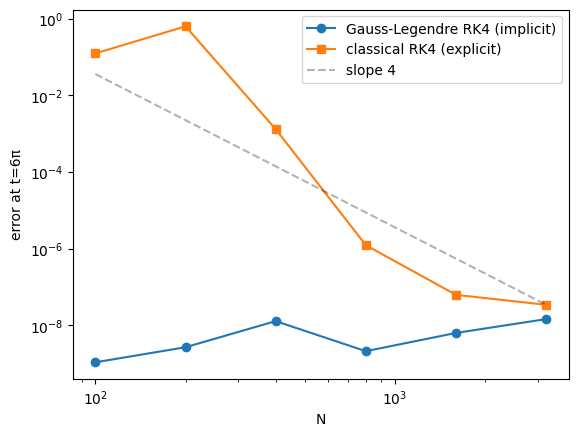

In [2]:
sq3 = np.sqrt(3)
GL4 = (np.array([[1/4, (3 - 2*sq3)/12], [(3 + 2*sq3)/12, 1/4]]),
       np.array([0.5, 0.5]), np.array([(3 - sq3)/6, (3 + sq3)/6]))

alpha = 20.0
def f1(t, y):
    return alpha / 2 * np.cos(t) * (1 - y ** 2)
def exact1(t):
    return np.tanh(alpha * np.sin(t) / 2)

T = 6 * np.pi
N_values = [100, 200, 400, 800, 1600, 3200]
y_ex = exact1(T)

gl4_errors, rk4_errors, gl4_times, rk4_times = [], [], [], []
for N in N_values:
    t0 = time.time()
    y_gl4 = implicit_rk_integrate(f1, 0.0, [0.0], T, N, GL4)[0]
    gl4_times.append(time.time() - t0)
    gl4_errors.append(abs(y_gl4 - y_ex))

    t0 = time.time()
    y_rk4 = explicit_rk_integrate(f1, 0.0, 0.0, T, N, EXPLICIT_TABLEAUS["RK4"])
    rk4_times.append(time.time() - t0)
    rk4_errors.append(abs(y_rk4 - y_ex))

print("    N   GL4 error   GL4 time   RK4 error   RK4 time")
for N, eg, tg, er, tr in zip(N_values, gl4_errors, gl4_times, rk4_errors, rk4_times):
    print(f"{N:5d}   {eg:.3e}   {tg:6.3f}s   {er:.3e}   {tr:7.4f}s")
print(f"RK4 observed order: {observed_order(N_values, rk4_errors):.2f} (theoretical 4)")

Nv = np.array(N_values, dtype=float)
plt.figure()
plt.loglog(Nv, gl4_errors, 'o-', label='Gauss-Legendre RK4 (implicit)')
plt.loglog(Nv, rk4_errors, 's-', label='classical RK4 (explicit)')
plt.loglog(Nv, rk4_errors[-1] * (Nv[-1] / Nv) ** 4, 'k--', alpha=0.3, label='slope 4')
plt.xlabel('N')
plt.ylabel('error at t=6π')
plt.legend()
plt.show()


# Exercise 2

stiffest eigenvalue magnitude: 316.22792397446034
N=   10  CN=7.400e+02  TR-BDF2=4.710e-02  Heun=4.076e+33
N=   20  CN=7.018e+02  TR-BDF2=4.593e-02  Heun=6.997e+56
N=   50  CN=2.812e+01  TR-BDF2=4.563e-02  Heun=1.169e+97
N=  100  CN=5.097e+02  TR-BDF2=4.559e-02  Heun=6.933e+132
N=  200  CN=4.269e+01  TR-BDF2=4.558e-02  Heun=3.528e+143
N=  500  CN=9.540e-01  TR-BDF2=3.930e-02  Heun=9.716e+49
N= 1000  CN=6.184e-02  TR-BDF2=6.642e-02  Heun=3.091e+06
N= 2000  CN=2.067e-02  TR-BDF2=1.057e-01  Heun=4.607e-01
N= 4000  CN=6.907e-02  TR-BDF2=2.944e-02  Heun=7.304e-02
N= 8000  CN=1.322e-02  TR-BDF2=5.882e-03  Heun=1.231e-02
N=16000  CN=2.858e-03  TR-BDF2=1.354e-03  Heun=4.966e-03
N=32000  CN=6.844e-04  TR-BDF2=3.304e-04  Heun=1.336e-03
N=64000  CN=1.692e-04  TR-BDF2=8.205e-05  Heun=3.382e-04
CN observed order: 2.09
TR-BDF2 observed order: 2.05


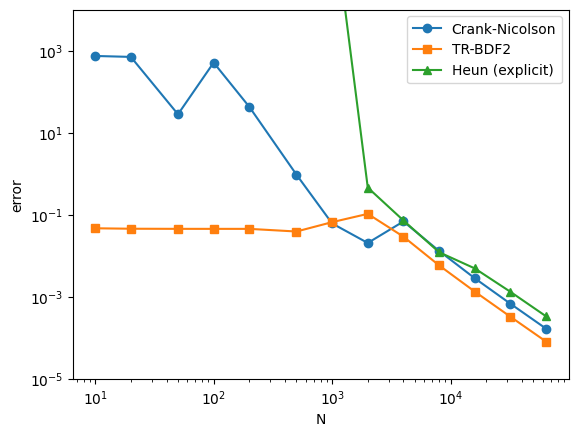

In [3]:
A2 = np.array([
    [0, 0, 1, 0],
    [0, 0, 0, 1],
    [-1.1, 0.1, -0.01, 0],
    [100000, -100000, 0, -10],
])
y0_2 = np.array([1.0, 5.0, 0.0, 0.0])
T2 = 2.0
y_exact2 = expm(A2 * T2) @ y0_2
print("stiffest eigenvalue magnitude:", np.max(np.abs(np.linalg.eigvals(A2))))

N_values2 = [10, 20, 50, 100, 200, 500, 1000, 2000, 4000, 8000, 16000, 32000, 64000]
f2 = lambda t, y: A2 @ y
cn_err, trbdf2_err, heun_err = [], [], []
for N in N_values2:
    y_cn = crank_nicolson_linear(A2, y0_2, T2, N)
    y_tr = tr_bdf2_linear(A2, y0_2, T2, N)
    y_he = explicit_rk_integrate(f2, 0.0, y0_2, T2, N, EXPLICIT_TABLEAUS["Heun"])
    cn_err.append(np.linalg.norm(y_cn - y_exact2))
    trbdf2_err.append(np.linalg.norm(y_tr - y_exact2))
    heun_err.append(np.linalg.norm(y_he - y_exact2))

for N, ec, et, eh in zip(N_values2, cn_err, trbdf2_err, heun_err):
    print(f"N={N:5d}  CN={ec:.3e}  TR-BDF2={et:.3e}  Heun={eh:.3e}")
print(f"CN observed order: {observed_order(N_values2, cn_err):.2f}")
print(f"TR-BDF2 observed order: {observed_order(N_values2, trbdf2_err):.2f}")
# print(f"Heun observed order: {observed_order(N_values2, heun_err):.2f}")
Nv2 = np.array(N_values2, dtype=float)
plt.figure()
plt.loglog(Nv2, cn_err, 'o-', label='Crank-Nicolson')
plt.loglog(Nv2, trbdf2_err, 's-', label='TR-BDF2')
plt.loglog(Nv2, heun_err, '^-', label='Heun (explicit)')
plt.ylim(1e-5, 1e4)
plt.xlabel('N')
plt.ylabel('error')
plt.legend()
plt.show()


# Exercise 3

SDIRK2 (order 2) vs Heun:
  N=   50  SDIRK2=3.188e-01  Heun=3.789e+00
  N=  100  SDIRK2=7.309e-02  Heun=6.877e-01
  N=  200  SDIRK2=1.756e-02  Heun=1.143e-01
  N=  400  SDIRK2=4.311e-03  Heun=2.145e-02
  N=  800  SDIRK2=1.069e-03  Heun=4.651e-03
  N= 1600  SDIRK2=2.661e-04  Heun=1.094e-03
  observed order: SDIRK2=2.01, Heun=2.23 (theoretical 2)
SDIRK3 (order 3) vs RK3:
  N=   50  SDIRK3=7.331e-01  RK3=9.260e-01
  N=  100  SDIRK3=1.166e-01  RK3=1.839e-01
  N=  200  SDIRK3=1.565e-02  RK3=2.518e-02
  N=  400  SDIRK3=1.992e-03  RK3=3.213e-03
  N=  800  SDIRK3=2.501e-04  RK3=4.034e-04
  N= 1600  SDIRK3=3.129e-05  RK3=5.047e-05
  observed order: SDIRK3=2.99, RK3=2.99 (theoretical 3)


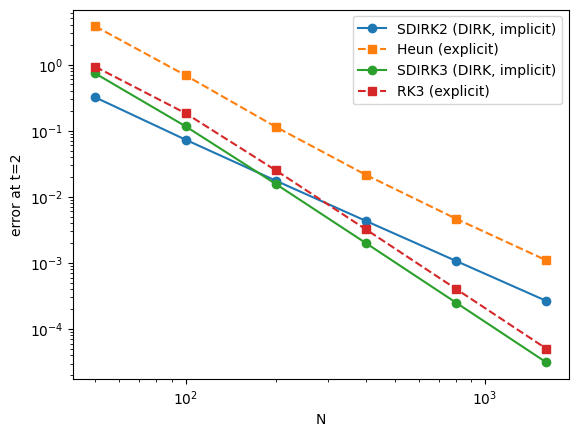

In [4]:
def lorenz(t, y, sigma=10.0, b=8.0/3.0, r=28.0):
    y1, y2, y3 = y
    return np.array([-sigma * y1 + sigma * y2, r * y1 - y2 - y1 * y3, y1 * y2 - b * y3])

y0_3 = [1.0, 1.0, 1.0]
T3 = 2.0  # kept short: Lorenz is chaotic, so a longer horizon would make any two
          # numerical trajectories diverge exponentially regardless of method accuracy
ref = solve_ivp(lorenz, [0, T3], y0_3, method="DOP853", rtol=1e-13, atol=1e-13)
y_ref3 = ref.y[:, -1]

# 2-stage SDIRK, order 2, L-stable
gamma2 = 1 - np.sqrt(2) / 2
SDIRK2 = (np.array([[gamma2, 0], [1 - gamma2, gamma2]]),
          np.array([1 - gamma2, gamma2]), np.array([gamma2, 1.0]))

# 3-stage SDIRK, order 3, L-stable (Alexander 1977)
gamma3 = 0.4358665215
b1_ = -(6 * gamma3 ** 2 - 16 * gamma3 + 1) / 4
b2_ = (6 * gamma3 ** 2 - 20 * gamma3 + 5) / 4
SDIRK3 = (np.array([[gamma3, 0, 0], [(1 - gamma3) / 2, gamma3, 0], [b1_, b2_, gamma3]]),
          np.array([b1_, b2_, gamma3]), np.array([gamma3, (1 + gamma3) / 2, 1.0]))

DIRK_TABLEAUS = {"SDIRK2": (SDIRK2, "Heun", 2), "SDIRK3": (SDIRK3, "RK3", 3)}

N_values3 = [50, 100, 200, 400, 800, 1600]
plt.figure()
for name, (dirk_tab, explicit_name, order) in DIRK_TABLEAUS.items():
    dirk_err, expl_err = [], []
    for N in N_values3:
        y_d = implicit_rk_integrate(lorenz, 0.0, y0_3, T3, N, dirk_tab)
        y_e = explicit_rk_integrate(lorenz, 0.0, np.array(y0_3), T3, N, EXPLICIT_TABLEAUS[explicit_name])
        dirk_err.append(np.linalg.norm(y_d - y_ref3))
        expl_err.append(np.linalg.norm(y_e - y_ref3))
    print(f"{name} (order {order}) vs {explicit_name}:")
    for N, ed, ee in zip(N_values3, dirk_err, expl_err):
        print(f"  N={N:5d}  {name}={ed:.3e}  {explicit_name}={ee:.3e}")
    print(f"  observed order: {name}={observed_order(N_values3, dirk_err):.2f}, "
          f"{explicit_name}={observed_order(N_values3, expl_err):.2f} (theoretical {order})")
    Nv3 = np.array(N_values3, dtype=float)
    plt.loglog(Nv3, dirk_err, 'o-', label=f'{name} (DIRK, implicit)')
    plt.loglog(Nv3, expl_err, 's--', label=f'{explicit_name} (explicit)')
plt.xlabel('N')
plt.ylabel('error at t=2')
plt.legend()
plt.show()


# Exercise 4

expm reference computed in 2.6s
spectral radius: 436.2587606147562
N=   10  CN=1.104e+00  TR-BDF2=5.588e-01  RK2(Heun)=3.788e+18
N=   20  CN=2.987e-01  TR-BDF2=1.466e-01  RK2(Heun)=9.321e+35
N=   50  CN=4.881e-02  TR-BDF2=2.373e-02  RK2(Heun)=2.859e+64
N=  100  CN=1.224e-02  TR-BDF2=5.942e-03  RK2(Heun)=6.006e+71
N=  200  CN=3.062e-03  TR-BDF2=1.486e-03  RK2(Heun)=2.599e+07
N=  300  CN=1.361e-03  TR-BDF2=6.605e-04  RK2(Heun)=2.723e-03
N=  500  CN=4.900e-04  TR-BDF2=2.378e-04  RK2(Heun)=9.802e-04
N=  800  CN=1.914e-04  TR-BDF2=9.288e-05  RK2(Heun)=3.829e-04
N= 1200  CN=8.507e-05  TR-BDF2=4.128e-05  RK2(Heun)=1.701e-04
N= 2000  CN=3.062e-05  TR-BDF2=1.486e-05  RK2(Heun)=6.125e-05
CN observed order: 2.00
TR-BDF2 observed order: 2.00


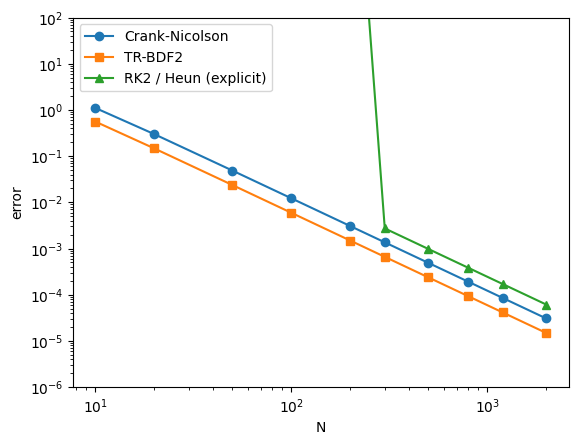

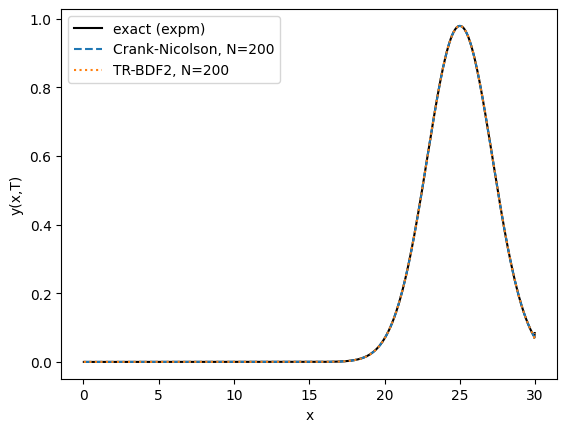

In [5]:
def build_adv_diff_matrix(M, L=30.0, u=10.0, nu=0.1):
    dx = L / M
    n = M - 1
    Amat = np.zeros((n, n))
    adv, diff = u / (2 * dx), nu / dx ** 2
    for i in range(n):
        Amat[i, i] = -2 * diff
        if i > 0:
            Amat[i, i - 1] = adv + diff
        if i < n - 1:
            Amat[i, i + 1] = -adv + diff
    return Amat, dx

M = 1000
L = 30.0
A4, dx = build_adv_diff_matrix(M, L=L)
x = np.arange(1, M) * dx
y0_4 = np.exp(-((x - 0.5 * L) / (0.1 * L)) ** 2)
T4 = 1.0

t0 = time.time()
y_exact4 = expm(A4 * T4) @ y0_4
print(f"expm reference computed in {time.time() - t0:.1f}s")
print("spectral radius:", np.max(np.abs(np.linalg.eigvals(A4))))

f4 = lambda t, y: A4 @ y
N_values4 = [10, 20, 50, 100, 200, 300, 500, 800, 1200, 2000]
cn_err4, trbdf2_err4, rk2_err4 = [], [], []
for N in N_values4:
    y_cn = crank_nicolson_linear(A4, y0_4, T4, N)
    y_tr = tr_bdf2_linear(A4, y0_4, T4, N)
    y_rk = explicit_rk_integrate(f4, 0.0, y0_4, T4, N, EXPLICIT_TABLEAUS["Heun"])
    cn_err4.append(np.linalg.norm(y_cn - y_exact4))
    trbdf2_err4.append(np.linalg.norm(y_tr - y_exact4))
    rk2_err4.append(np.linalg.norm(y_rk - y_exact4))

for N, ec, et, er in zip(N_values4, cn_err4, trbdf2_err4, rk2_err4):
    print(f"N={N:5d}  CN={ec:.3e}  TR-BDF2={et:.3e}  RK2(Heun)={er:.3e}")
print(f"CN observed order: {observed_order(N_values4, cn_err4):.2f}")
print(f"TR-BDF2 observed order: {observed_order(N_values4, trbdf2_err4):.2f}")

Nv4 = np.array(N_values4, dtype=float)
plt.figure()
plt.loglog(Nv4, cn_err4, 'o-', label='Crank-Nicolson')
plt.loglog(Nv4, trbdf2_err4, 's-', label='TR-BDF2')
plt.loglog(Nv4, rk2_err4, '^-', label='RK2 / Heun (explicit)')
plt.ylim(1e-6, 1e2)
plt.xlabel('N')
plt.ylabel('error')
plt.legend()
plt.show()

plt.figure()
plt.plot(x, y_exact4, 'k-', label='exact (expm)')
plt.plot(x, crank_nicolson_linear(A4, y0_4, T4, 200), '--', label='Crank-Nicolson, N=200')
plt.plot(x, tr_bdf2_linear(A4, y0_4, T4, 200), ':', label='TR-BDF2, N=200')
plt.xlabel('x')
plt.ylabel('y(x,T)')
plt.legend()
plt.show()
